In [26]:
from functions import *   # get_latest_forecast_cycle, calculate_forecast_range, convert_time_to_datetime64
from herbie import FastHerbie
import pandas as pd
import numpy as np
import xarray as xr
import warnings

# Suppress the specific FutureWarning message from cfgrib
warnings.filterwarnings(
    "ignore",
    # message="In a future version of xarray the default value for compat will change",
    message="In*",
    category=FutureWarning
)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# single point (longitude, latitude)
cityName = "Loveland, CO (KFNL)"
points = pd.DataFrame({"longitude": [-105.004186], "latitude": [40.451685]})

print("Fetching HRRR data...")

# Determine the latest model cycle (uses functions.get_latest_forecast_cycle)
init_hrrr = get_latest_forecast_cycle(model="HRRR")

# Determine forecast steps to request (uses functions.calculate_forecast_range)
fxx_hrrr = calculate_forecast_range(init_hrrr, model="HRRR")

# Request fields from Herbie
H_hrrr = FastHerbie([init_hrrr], model="hrrr", product="sfc", fxx=fxx_hrrr)

# 2 m temperature: extract, convert K->F, compute max/min for the point
t2m_hrrr = H_hrrr.xarray("TMP:2 m above", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['t2m'].sel(point=0)[1:]  # skip first timestep which is included for precip only
t2m_hrrr = (t2m_hrrr - 273.15) * 1.8 + 32
tmax_hrrr = float(t2m_hrrr.max().values)
tmin_hrrr = float(t2m_hrrr.min().values)
init_times_hrrr = convert_time_to_datetime64(t2m_hrrr.time.values)
valid_times_hrrr = convert_time_to_datetime64(t2m_hrrr.valid_time.values)

# 10 m wind speed (HRRR exposes :WIND / si10)
si10_hrrr = H_hrrr.xarray(":WIND", backend_kwargs={'decode_times': False}
                            ).herbie.pick_points(points, method="nearest")['max_10si'].sel(point=0)[1:]  # skip first timestep which is included for precip only
wind_max_hrrr = float(si10_hrrr.max().values) * 1.94384 # convert from m/s to knots

# Total precipitation from APCP (convert mm -> in); compute 24h accumulation as in prior script
tp_hrrr = H_hrrr.xarray("APCP", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
tp_hrrr = tp_hrrr * 0.0393701   # mm -> inches (1 mm -> 0.0393701 in)

# Subtract first timestep to get accumulation over the requested period (as in original)
tp_hrrr = tp_hrrr[1:] - tp_hrrr[0]
precip_hrrr = float(tp_hrrr.max().values)

# build and print a simple table using pandas for formatting (HRRR)
df = pd.DataFrame({
    "Model": ["HRRR"],
    "High (°F)": [round(tmax_hrrr, 2)],
    "Low (°F)": [round(tmin_hrrr, 2)],
    "Precipitation (in)": [round(precip_hrrr, 3)],
    "Wind Speed (kt)": [round(wind_max_hrrr, 2)],
    "Model Init": [pd.Timestamp(init_hrrr).isoformat()],
    "Valid Range": [f"{valid_times_hrrr[0]} - {valid_times_hrrr[-1]}"]
})

title = f"Forecasting for {cityName} (HRRR)"
print(title)
print(df.to_string(index=False))


Fetching HRRR data...
Forecasting for Loveland, CO (KFNL) (HRRR)
Model  High (°F)  Low (°F)  Precipitation (in)  Wind Speed (kt)          Model Init                   Valid Range
 HRRR      70.59     53.73                 0.0              8.5 2025-09-04T18:00:00 2025-09-05T06 - 2025-09-06T05


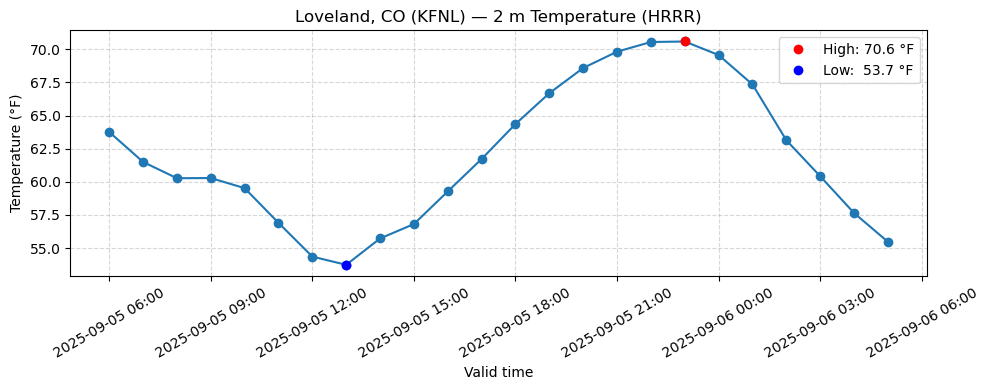

In [29]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

times = pd.to_datetime(valid_times_hrrr)  # numpy.datetime64 -> DatetimeIndex
temps = t2m_hrrr.values  # Fahrenheit values from HRRR

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(times, temps, marker='o', linestyle='-')

# highlight max/min
idx_max = int(np.nanargmax(temps))
idx_min = int(np.nanargmin(temps))
ax.plot(times[idx_max], temps[idx_max], 'ro', label=f"High: {temps[idx_max]:.1f} °F")
ax.plot(times[idx_min], temps[idx_min], 'bo', label=f"Low:  {temps[idx_min]:.1f} °F")

ax.set_title(f"{cityName} — 2 m Temperature (HRRR)")
ax.set_xlabel("Valid time")
ax.set_ylabel("Temperature (°F)")
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=30)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

# IFS

In [1]:
from functions import *   # get_latest_forecast_cycle, calculate_forecast_range, convert_time_to_datetime64
from herbie import FastHerbie
import pandas as pd
import numpy as np
import xarray as xr
import warnings

# Suppress the specific FutureWarning message from cfgrib
warnings.filterwarnings(
    "ignore",
    # message="In a future version of xarray the default value for compat will change",
    message="In*",
    category=FutureWarning
)
cityName = "Grand Forks, ND (KGFK)"
points = pd.DataFrame({"longitude": [-97.1763], "latitude": [47.9205]})


init_ifs = get_latest_forecast_cycle(model="IFS")
fxx_ifs = calculate_forecast_range(init_ifs, model="IFS")
H_ifs = FastHerbie([init_ifs], model="ifs", product="oper", fxx=fxx_ifs)


In [42]:
init_ifs

Timestamp('2025-09-04 12:00:00')

In [2]:
tp_ifs = H_ifs.xarray(":tp:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
tp_ifs

<xarray.DataArray 'tp' (step: 9)> Size: 36B
array([0.01031113, 0.01115417, 0.0111618 , 0.0111618 , 0.0111618 ,
       0.01117706, 0.01117706, 0.01117706, 0.01117706], dtype=float32)
Coordinates:
    time                 int64 8B 1756987200
  * step                 (step) timedelta64[ns] 72B 0 days 15:00:00 ... 1 day...
    surface              float64 8B 0.0
    latitude             float64 8B 48.0
    longitude            float64 8B -97.25
    valid_time           (step) float64 72B 1.757e+09 1.757e+09 ... 1.757e+09
    gribfile_projection  object 8B None
    point_grid_distance  float64 8B 10.4
    point_longitude      float64 8B -97.18
    point_latitude       float64 8B 47.92
Attributes: (12/34)
    GRIB_paramId:                             228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      1038240
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_shortName:                           tp
    GRIB_units:                               m
    long_name:                                Total precipitation
    units:                                    m
    standard_name:                            unknown
    grid_mapping:                             gribfile_projection

In [3]:
convert_time_to_datetime64(tp_ifs.valid_time.values)

array(['2025-09-05T03', '2025-09-05T06', '2025-09-05T09', '2025-09-05T12',
       '2025-09-05T15', '2025-09-05T18', '2025-09-05T21', '2025-09-06T00',
       '2025-09-06T03'], dtype='datetime64[h]')

In [10]:
precip_m

<xarray.DataArray 'tp' (step: 8)> Size: 32B
array([0.00084305, 0.00085068, 0.00085068, 0.00085068, 0.00086594,
       0.00086594, 0.00086594, 0.00086594], dtype=float32)
Coordinates:
    time                 int64 8B 1756987200
  * step                 (step) timedelta64[ns] 64B 0 days 18:00:00 ... 1 day...
    surface              float64 8B 0.0
    latitude             float64 8B 48.0
    longitude            float64 8B -97.25
    gribfile_projection  object 8B None
    point_grid_distance  float64 8B 10.4
    point_longitude      float64 8B -97.18
    point_latitude       float64 8B 47.92

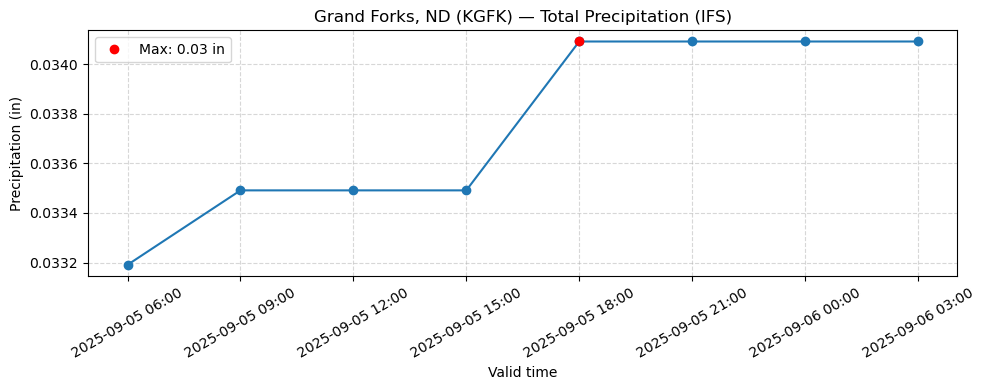

In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# plot total precipitation from IFS (convert meters -> inches, subtract first step to get accumulation)
times = pd.to_datetime(convert_time_to_datetime64(tp_ifs.valid_time.values[1:]))
precip_m = tp_ifs[1:] - tp_ifs.isel(step=0)        # remove initial accumulation baseline
precip_in = precip_m * 39.3701                 # meters -> inches

precip_vals = precip_in.values

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(times, precip_vals, marker='o', linestyle='-')

# highlight max accumulation
idx_max = int(np.nanargmax(precip_vals))
ax.plot(times[idx_max], precip_vals[idx_max], 'ro', label=f"Max: {precip_vals[idx_max]:.2f} in")

ax.set_title(f"{cityName} — Total Precipitation (IFS)")
ax.set_xlabel("Valid time")
ax.set_ylabel("Precipitation (in)")
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=30)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()
